In [1]:
from typing import Annotated, List, TypedDict
from collections.abc import Sequence
from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from langchain_deepseek import ChatDeepSeek
from operator import add
from dotenv import load_dotenv
from pydantic import BaseModel, Field

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

# 结构化输出的 Schema
class Section(BaseModel):
    name: str = Field(
        description="报告的章节名称",
    )
    description: str = Field(
        description="本节主题和核心思想的概述",
    )

class Sections(BaseModel):
    sections: List[Section] = Field(
        description="报告的章节列表",
    )

# 编排器
planner = model.with_structured_output(Sections)

# 图状态
class OverAllState(TypedDict):
    topic: str  # 报告主题
    sections: list[Section]  # 报告章节列表
    completed_sections: Annotated[
        list, add
    ]  # 所有工作节点并行写入该字段
    final_report: str  # 最终报告

# 工作节点状态
class WorkerState(TypedDict):
    section: Section
    completed_sections: Annotated[list, add]

# 节点
def orchestrator(state: OverAllState) -> OverAllState:
    """编排器：生成报告编写计划"""
    # 生成报告章节规划
    report_sections = planner.invoke(
        [
            SystemMessage(content="为这份报告生成一个章节规划。"),
            HumanMessage(content=f"报告主题如下：{state['topic']}"),
        ]
    )
    return {"sections": report_sections.sections}

def model_call(state: WorkerState) -> WorkerState:
    """工作节点：编写报告中的一个章节"""
    # 生成章节内容
    section = model.invoke(
        [
            SystemMessage(
                content=(
                    "根据提供的章节名称和章节描述编写报告内容。"
                    "不要在每个章节前添加额外的开场说明。"
                    "使用 Markdown 格式。"
                )
            ),
            HumanMessage(
                content=(
                    f"章节名称：{state['section'].name}\n"
                    f"章节描述：{state['section'].description}"
                )
            ),
        ]
    )
    # 将生成的章节写入已完成章节列表
    return {"completed_sections": [section.content]}

def synthesizer(state: OverAllState) -> OverAllState:
    """将所有章节合成为完整报告"""
    # 获取所有已完成的章节
    completed_sections = state["completed_sections"]
    # 将已完成章节拼接为最终报告
    completed_report_sections = "\n\n---\n\n".join(completed_sections)
    return {"final_report": completed_report_sections}

# 条件边函数：为规划中的每个章节创建一个 model_call 工作节点
def assign_workers(state: OverAllState) -> Sequence[Send]:
    """为规划中的每个章节分配一个工作节点"""
    # 使用 Send API 并行启动各个章节的编写任务
    return [Send("model_call", {"section": s}) for s in state["sections"]]

# 构建工作流
builder = StateGraph(state_schema=OverAllState)

# 添加节点
builder.add_node("orchestrator", orchestrator)
builder.add_node("model_call", model_call)
builder.add_node("synthesizer", synthesizer)

# 添加边，连接各个节点
builder.add_edge(START, "orchestrator")
builder.add_conditional_edges(
    "orchestrator",
    assign_workers,
    ["model_call"],
)
builder.add_edge("model_call", "synthesizer")
builder.add_edge("synthesizer", END)

# 编译工作流
graph = builder.compile()

# 调用工作流
state = graph.invoke(
    {"topic": "撰写一份关于大语言模型缩放定律的报告"}
)

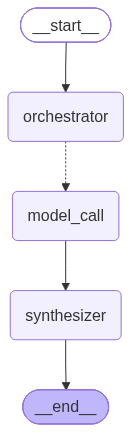

# 引言：为什么缩放定律重要

## 缩放定律的核心地位

缩放定律（Scaling Laws）在大语言模型研发中占据核心地位，其根本原因在于它揭示了模型性能与参数量、数据量、计算量之间可预测的幂律关系。在这一关系被发现之前，大规模模型训练在很大程度上依赖经验直觉与反复试错，常被形容为"炼金术"；而缩放定律的确立，使研发者能够在训练开始之前对性能进行定量预估，从而将大规模训练转变为可建模、可规划、可验证的"工程科学"。这一转变不仅改变了研究范式，也重塑了产业界配置资源与制定技术路线的方式。

## 本报告的写作目标与面向读者

本报告旨在系统阐述缩放定律的基本内涵、经验规律及其对大规模语言模型研发实践的指导意义。报告面向的读者包括从事大模型研发的研究人员与工程师、负责技术路线与资源规划的技术管理者，以及对大模型训练方法论感兴趣的高校师生与产业观察者。在内容组织上，报告首先介绍缩放定律的基本形式与关键结论，继而讨论其在数据与计算预算分配、训练可行性预判中的具体应用，随后分析其适用边界与局限性，最后结合实践给出研发决策建议，力求兼顾理论严谨性与工程可操作性。

## 缩放定律的实际价值

缩放定律的实际价值集中体现在三个方面。其一，在资源分配决策上，幂律关系为参数量、数据量与计算量之间的权衡提供了量化依据，使有限的算力与数据预算能够被配置到边际收益最高的方向。其二，在训练可行性预判上，研发者可以借助小规模实验拟合的缩放曲线，外推大规模训练的预期损失与性能水平，从而在投入巨额算力之前评估方案的合理性。其三，在研发风险控制上，缩放定律有助于识别收益递减区间与潜在的训练失败模式，降低盲目扩张带来的资源浪费与项目风险。正是这些实际价值，使缩放定律成为连接理论研究与工程实践的关键桥梁，也是本报告展开讨论的逻辑起点。

---

# 缩放定律的理论基础与数学形式

## 1 基本思想

缩放定律（scaling laws）刻画的是模型损失随规模要素（参数量、数据量、计算量）变化所呈现的规律性关系。其核心经验观察是：在相当宽的范围内，交叉熵损失随任一规模要素的增加而单调下降，且下降速率呈现稳定的幂律特征。这一规律性使得在小规模实验中测得的损失曲线可以外推至更大规模，从而为训练前的资源分配与规模决策提供定量依据。

缩放定律的基本假设是损失的下降由规模要素主导，而非由具体架构细节或训练技巧主导。换言之，在给定的模型族与数据分布下，损失近似是规模要素的平滑函数，架构差异主要体现为系数与指数的偏移，而不改变幂律的函数形式。这一假设的成立范围构成缩放定律适用性的边界。

## 2 典型数学形式

### 2.1 单要素幂律

对参数量 N、训练数据量 D 与计算量 C，损失分别满足：

$$L(N) \propto N^{-\alpha}, \qquad L(D) \propto D^{-\beta}, \qquad L(C) \propto C^{-\gamma}$$

其中指数 α、β、γ 为正数，反映损失对相应规模要素的敏感程度。取对数后，幂律退化为线性关系：

$$\log L = \log k - \alpha \log N$$

幂律形式意味着规模每扩大一个固定倍数，损失下降一个固定比例（而非固定绝对量），因而存在明显的边际收益递减：规模翻倍带来的损失降幅随基线规模增大而缩小。

### 2.2 含不可约损失项的组合形式

单要素幂律在规模趋于无穷时给出零损失，与实际不符。更完整的描述引入不可约损失项 $L_\infty$（由数据分布本身的熵决定），并常以加性组合形式同时纳入参数量与数据量：

$$L(N, D) = L_\infty + \left(\frac{N_c}{N}\right)^{\alpha} + \left(\frac{D_c}{D}\right)^{\beta}$$

其中 $N_c$、$D_c$ 为特征尺度常数。该形式表明：当某一要素受限时，另一要素的继续增加收益迅速饱和；损失的下界由 $L_\infty$ 给出，任何规模扩张都无法突破。计算量受限下的形式通常写作 $L(C) = L_\infty + (C_c/C)^{\gamma}$，其中 γ 与 α、β 通过计算预算约束 $C \approx 6ND$ 相联系。

组合形式的重要推论是要素间的权衡：在固定计算预算下，参数量与数据量存在最优配比，且该配比随预算增大按幂律移动（Chinchilla 型分配）。这使缩放定律从描述性工具转变为资源分配的设计依据。

## 3 幂律背后的直觉

**高维统计学习视角。** 随着参数量或数据量增加，模型可用的有效样本与有效容量同步增长，估计误差按多项式速率衰减。在平滑性假设下，非参数估计的误差上界本身即为规模要素的负幂函数，幂指数由目标函数的平滑度与输入维度共同决定。这为幂律形式提供了统计学习理论的解释来源。

**有效自由度视角。** 模型的实际表达能力不由名义参数总量决定，而由数据所约束的有效自由度决定。规模扩张使有效自由度提升，但提升速率递减：新增参数或样本所覆盖的方向逐渐与已有方向冗余，导致损失下降趋缓。幂指数可理解为有效自由度随规模增长的弹性。

**损失景观视角。** 训练过程在高维损失景观中寻优，规模增大使景观中的良好解区域更易被触及，损失的下降与优化难度、解空间的冗余度相关。经验上不同架构、不同优化设置下的指数取值相近，提示幂律反映的是规模要素与损失之间的结构性关系，而非特定训练细节的产物。

## 4 指数取值范围与经验拟合

经验研究中，α、β、γ 通常落在 0.05–0.5 的量级区间，具体取值依模型族、数据分布与损失定义而异。指数偏大意味着该要素的边际收益衰减较慢，扩大该要素更为划算；指数偏小则相反。含不可约项时，拟合得到的指数与 $L_\infty$ 存在相关性，需联合估计而非逐项独立拟合。

**拟合方法。** 标准做法是在对数空间进行线性回归：对单要素幂律，取 $(\log N, \log L)$ 做最小二乘拟合，斜率即 $-\alpha$；对含不可约项的组合形式，$L_\infty$ 非线性进入模型，通常采用非线性最小二乘，或在给定 $L_\infty$ 网格上对对数线性模型做搜索以最小化残差。拟合时应使用多个规模点、覆盖足够宽的规模跨度，并报告残差与置信区间；仅用两三个点拟合的指数不稳定，不宜用于外推。

## 5 拟合外推的可靠性与边界

外推可靠性受三方面限制。

**其一，函数形式的设定风险。** 幂律是经验规律而非定理。若真实关系在更大规模处出现指数变化、饱和转折或相变（如能力涌现），基于小规模拟合的外推将系统性偏离。含不可约项的形式虽改善了大规模行为，但 $L_\infty$ 与指数在小规模数据上往往不可辨识，外推对拟合区间的选择敏感。

**其二，分布偏移风险。** 缩放定律描述的是固定数据分布下的损失。数据分布变化、数据质量差异或去重策略改变都会移动系数乃至指数，使跨分布的拟合参数不可直接迁移。

**其三，适用范围边界。** 定律在训练充分（接近计算最优）、规模处于拟合区间内的条件下最为可靠；在训练不足（欠训练）、规模远超出拟合区间、或接近数据耗尽时，外推误差显著增大。因此，缩放定律的实践使用应以区间内验证为前提，将外推结果视为带不确定性的预测而非确定结论，并在可行时用中等规模实验对预测进行校验。

综上，缩放定律以幂律及其含不可约项的组合形式为数学骨架，其理论直觉来自高维统计学习、有效自由度与损失景观，其经验价值依赖于对数空间拟合的稳健性与对适用边界的清醒认识。

---

# 代表性研究成果梳理

## 一、早期缩放定律：优先扩大参数量

Kaplan 等人（2020）的工作奠定了大模型缩放研究的实证基础。其核心主张是：在固定计算预算下，模型性能（以交叉熵损失衡量）随参数量、数据量与计算量呈幂律下降，且**参数量的扩展效率高于数据量**。据此，Kaplan 等人建议在计算预算增加时，应将大部分增量投入到模型参数规模上，而非训练数据规模。这一结论直接塑造了 GPT-3 时代"大参数、相对少数据"的训练范式。

该研究在实验设定上以 Transformer 语言模型为对象，覆盖多个数量级的参数量与数据量组合，拟合区间主要落在中小规模模型上，并通过外推预测大规模下的最优配置。其损失测量采用标准的下一 token 预测交叉熵，优化器与学习率调度沿用当时主流配置。

## 二、Chinchilla 修正：计算最优的等比例扩展

Hoffmann 等人（2022）的 Chinchilla 工作对 Kaplan 的结论提出了系统性修正。其核心发现是：**参数量与训练数据量应等比例扩展**，在计算最优配置下，每个参数大约对应 20 个训练 token。这意味着此前的许多大模型"参数过大、数据不足"，处于欠训练状态；在相同计算预算下，更小的模型配合更多数据可以达到更低的损失。

Chinchilla 通过控制变量式的多组训练实验（固定计算预算、改变参数量与数据量配比）重新拟合了缩放曲线，并采用更精细的学习率调度与训练配置。其与 Kaplan 结论的分歧主要来源于：

- **实验设定差异**：Chinchilla 在更大规模、更接近实际训练条件的配置下重新测量，而 Kaplan 的拟合区间偏向中小模型并依赖外推；
- **学习率调度**：Chinchilla 为每个模型规模单独调优学习率调度（包括余弦调度与训练步数匹配），而 Kaplan 的设置未对每个配置做同等程度的调优，导致小模型损失被高估，从而扭曲了最优配比的推断；
- **损失测量方式**：不同的评价 token 集与损失归一化方式会影响曲线拟合的斜率。

## 三、后续研究：数据受限、推理成本与数据重复

Chinchilla 之后的研究沿多条脉络展开：

**数据受限扩展**。Muennighoff 等人（2023）研究在高质量数据有限时重复训练数据的收益衰减规律，指出在数据重复约 4 个 epoch 以内，重复数据的价值接近新数据，但继续重复收益迅速下降；并进一步提出在数据受限条件下，应优先扩大参数量而非无限重复数据，形成对 Chinchilla 结论的边界条件修正。

**推理成本感知的扩展**。多项工作指出 Chinchilla 的"计算最优"仅考虑训练计算，忽略了部署阶段的推理成本。对于高调用量的模型，训练一个更小但训练更充分的模型（即"过度训练"于 Chinchilla 最优配比之外）在总拥有成本上更优。这解释了后续许多开源模型采用远超 20 tokens/参数比例训练的现象，也构成对 Chinchilla 结论在实际工程语境下的重要补充。

**多模态扩展**。后续研究将缩放分析扩展到图文等多模态设定，探讨不同模态数据量、模型规模与损失之间的幂律关系，发现模态间的数据配比本身构成新的扩展维度，最优配比随规模变化而漂移。

## 四、分歧来源的综合解释

各研究在结论上的差异并非简单的对错关系，而是实验条件与建模假设不同的结果：

1. **优化器与超参调优**：Adam 及其变体的超参、权重衰减、梯度裁剪等设置随规模调整的程度不同，会系统性改变小模型与大模型的相对效率，从而影响最优配比推断；
2. **学习率调度**：是否按模型规模匹配训练步数与调度形状，是 Kaplan 与 Chinchilla 分歧的关键来源之一；
3. **数据质量**：高质量数据的有效 token 数不同于原始 token 数，数据去重与过滤会改变"数据量"的实际含义，进而改变 20 tokens/参数这一经验比例的适用性；
4. **损失测量方式**：评价集选择、token 归一化、是否包含特定领域数据，都会影响缩放曲线的斜率与截距；
5. **外推与拟合区间**：从小规模拟合外推到大规模本身存在误差，拟合区间的覆盖范围直接决定结论的可靠性。

综上，缩放定律的演进呈现出一条清晰的修正链条：从"优先扩参数"到"参数与数据等比例"，再到引入数据受限、推理成本与多模态维度。每一次修正都源于实验设定或优化实践的细化，而非对幂律关系本身的否定。

---

# 计算最优分配与训练策略含义

## 一、计算最优框架的基本设定

计算最优（compute-optimal）框架的核心问题是：在给定算力预算 \(C\) 的约束下，如何把预算分配给模型参数量 \(N\) 与训练 token 数 \(D\)，使最终损失最小。其基本出发点是将训练总算力近似分解为

\[
C \approx 6ND
\]

（前向与反向传播的浮点运算量之和，系数 6 为常用近似），并假设损失对 \(N\)、\(D\) 具有可分离的幂律形式

\[
L(N,D) = L_\infty + \left(\frac{N_c}{N}\right)^{\alpha} + \left(\frac{D_c}{D}\right)^{\beta},
\]

其中 \(L_\infty\) 为不可约损失，\(N_c, D_c\) 为常数尺度，\(\alpha, \beta\) 为各自缩放指数。该形式的合理性来自大量经验拟合：在宽广的 \(N\)、\(D\) 范围内，损失对二者均呈幂律下降，且两项近似可加。

## 二、最优解的推导与形式

在约束 \(6ND = C\) 下最小化上述损失，构造拉格朗日函数并对 \(N\)、\(D\) 求偏导，可得一阶条件

\[
\alpha \left(\frac{N_c}{N}\right)^{\alpha} = \beta \left(\frac{D_c}{D}\right)^{\beta},
\]

即最优分配要求参数量项与数据量项的“边际收益”相等。结合约束解得

\[
N^* \propto C^{a}, \qquad D^* \propto C^{b}, \qquad a = \frac{\beta}{\alpha+\beta},\quad b = \frac{\alpha}{\alpha+\beta},
\]

且 \(a + b = 1\)，即算力增长按固定比例在参数与数据之间分摊。指数 \(a\)、\(b\) 完全由缩放指数决定：\(\beta\) 相对 \(\alpha\) 越大（数据侧收益衰减越慢），最优解越偏向增加数据、控制参数规模。当 \(\alpha \approx \beta\) 时，\(a \approx b \approx 0.5\)，即参数与数据近似等比例扩张——这与早期“随算力等比例增大模型”的直觉一致，但推导表明它只是特定指数关系下的特例。

由此还可得到最优损失随算力的幂律下降：

\[
L^*(C) = L_\infty + K \cdot C^{-\gamma}, \qquad \gamma = \frac{\alpha\beta}{\alpha+\beta},
\]

其中 \(K\) 为常数。\(\gamma\) 刻画了“花同样的算力能换来多少损失下降”，是评估不同缩放策略效率的核心指标。

需要强调的是，上述推导给出的是**训练阶段**的最优解。若考虑模型将被大量推理调用，则目标函数应改为训练算力与推理算力之和的联合约束，最优解会系统性地向“更小模型、更多数据”偏移：推理成本随参数量线性增长、随调用次数放大，因此把一部分训练预算从参数转移到数据（即训练更久的小模型）可以在总拥有成本上更优。这一偏移的幅度取决于推理调用量与训练规模之比，调用越密集，偏移越显著。

## 三、各训练超参与模型形状的缩放行为

计算最优框架不仅决定 \(N\) 与 \(D\)，还要求配套的超参与形状随规模协同缩放，否则实测损失会偏离预测曲线。

**学习率。** 在批量大小固定时，最优学习率随模型规模增大而下降，近似呈幂律 \(\eta^* \propto N^{-\kappa}\)（\(\kappa\) 为小的正指数）。其机理是：大模型的损失曲率更陡、对步长更敏感，过大的学习率会引发训练不稳定或末期损失抬升。实践中常配合 warmup 与余弦衰减，并按目标 token 数调整衰减终点。

**批量大小。** 存在“临界批量”（critical batch size）\(B_{\text{crit}}\)，低于它时增大批量可近乎线性地减少所需步数，高于它时收益迅速饱和。\(B_{\text{crit}}\) 随训练损失（即随规模）增大而增大，因此大模型训练普遍采用更大的批量，并相应上调学习率（线性或平方根缩放规则），以维持每 token 的有效更新量。

**序列长度。** 长上下文带来注意力计算随序列长度的二次增长，使“每 token 算力”不再是常数。在固定算力下延长序列，需要相应压缩其他维度的预算；同时长序列训练的有效批量（以 token 计）与梯度噪声结构发生变化，通常需要调整学习率与批量。位置编码外推、注意力稀疏化等设计也会改变序列长度维度的缩放斜率。

**模型形状。** 在参数量固定时，宽深比存在最优区间：过深难以优化、过宽参数效率低，经验上深度与宽度应协同增长，而非单维扩张。对 MoE 架构，形状维度还包括专家数 \(E\) 与激活专家数 \(k\)：总算力近似正比于激活参数量，而显存与通信成本正比于总参数量，因此 MoE 的最优分配问题变为在“激活参数—总参数—token 数”三者间求解，其最优解通常比稠密模型更偏向增大总参数量与数据量、控制激活参数量。

## 四、与现代架构的结合

**与 MoE 的结合。** MoE 将参数量与每 token 算力解耦，使 \(C \approx 6 N_{\text{act}} D\) 中的 \(N_{\text{act}}\) 远小于总参数 \(N_{\text{tot}}\)。计算最优框架在此需扩展为联合优化 \((N_{\text{act}}, N_{\text{tot}}, D)\)：在固定算力下，增大 \(N_{\text{tot}}\) 可提升容量而不成比例增加算力，但受显存、通信与负载均衡约束；因此最优解呈现出“更大总参数、更多数据、受控激活参数”的形态。专家数、专家粒度与路由策略的选择，本质上是在容量收益与系统开销之间做权衡，需纳入缩放曲线的拟合。

**与长上下文的结合。** 长上下文改变了每 token 的算力系数（注意力项随长度增长），使算力约束从 \(6ND\) 变为依赖平均序列长度的形式。相应地，最优 \(N^*\)、\(D^*\) 的指数会随序列长度配置而变化：若训练数据以长序列为主，等效算力消耗上升，最优解倾向于在参数与数据之间重新分配，并更依赖稀疏注意力等降低单位 token 成本的结构。长上下文还与数据配比耦合——高质量长文档的稀缺性会限制 \(D\) 的有效增长，使实际最优解偏离纯理论预测。

**综合含义。** 计算最优框架的价值不在于给出唯一的数字配方，而在于提供一套可检验的推理链条：由缩放指数推出分配指数，由分配指数推出损失—算力斜率，再由推理成本、架构稀疏性与数据可得性修正最优解。对训练策略的直接启示是：应把超参（学习率、批量、序列长度）与形状（宽深比、专家配置）视为与 \(N\)、\(D\) 联动的缩放变量，在目标算力档位上分别拟合、联合验证，而不是沿用固定配方；同时区分“训练最优”与“部署最优”，在推理密集的场景中主动选择更小模型、更多数据的配置，并以实测缩放曲线而非外推直觉作为决策依据。

---

# 缩放定律的实践应用与工程价值

## 一、从理论曲线到研发决策工具

缩放定律的价值不在于解释过去，而在于约束未来的决策。工程视角下，它是一套“用便宜实验预测昂贵实验”的外推工具：以可承受的小规模训练为探针，估计损失随模型规模、数据量、计算量变化的幂律关系，再据此判断大模型投入的预期回报。其核心假设是幂律关系在数个数量级内保持稳定，因此对数尺度上的线性拟合可以跨越规模外推。

## 二、小规模试验外推大模型性能

标准做法是在目标架构与数据管线下训练一族小模型（如参数量跨 4–5 个数量级、每个规模配多组数据量），记录最终损失，在对数坐标下拟合：

$$L(N, D) = E + \frac{A}{N^{\alpha}} + \frac{B}{D^{\beta}}$$

其中 $N$ 为参数量、$D$ 为训练 token 数、$E$ 为不可约损失。拟合得到 $(\alpha, \beta, E)$ 后，即可外推目标规模下的预期损失，并求解给定计算预算 $C \approx 6ND$ 下的最优分配。工程要点是：扫参模型必须与目标模型共享分词器、数据配比、优化器设置与精度策略，否则外推偏差会系统性放大；每个规模应至少覆盖两到三个数据量点，以便分离 $N$ 与 $D$ 的贡献。

## 三、预判训练是否值得投入

在启动大规模训练前，用外推曲线回答三个问题：目标损失是否显著优于现有基线；达到该损失所需计算量对应的成本是否在预算内；曲线是否已接近不可约损失 $E$，即收益是否趋于饱和。若外推显示投入翻倍仅换来边际损失下降，应优先转向数据质量或架构改进而非单纯堆规模。这一判断可将“是否值得训练”从直觉决策转为带置信区间的定量评估。

## 四、计算预算设定与算力规划

缩放定律给出预算分配的一阶近似：在 $C = 6ND$ 约束下最小化损失，可得 $N^* \propto C^{\beta/(\alpha+\beta)}$、$D^* \propto C^{\alpha/(\alpha+\beta)}$。工程上需注意两点：一是该分配对拟合指数敏感，应做敏感性分析而非单点采用；二是实际规划还要叠加推理成本——面向高调用量的服务型模型，往往值得在训练阶段超额投入以换取更小、更便宜的推理模型，此时最优分配会偏离纯训练视角的结论。算力规划应把训练集群规模、并行策略可行性（如目标 $N$ 是否超出单集群显存与通信约束）一并纳入，避免外推出的“最优规模”在工程上不可实现。

## 五、训练异常检测与涌现能力预测

缩放定律提供了一条“预期损失轨迹”。训练过程中将实测损失与同计算量下的拟合预测对比，持续显著偏离即提示数据污染、学习率配置不当、数值不稳定或并行实现错误，可在早期止损。对涌现能力，应区分两类现象：一是平滑的损失下降在特定下游指标上表现为突变，可用损失外推间接预判；二是真正的能力门槛难以由损失曲线直接读出，需在小规模上对目标能力做定向评测并谨慎外推。工程建议是保留一组固定评测探针，随规模同步测量，避免仅凭训练损失判断能力。

## 六、指导数据配比与数据质量投入

将数据量 $D$ 作为独立维度拟合，可评估“多训 token”与“增大模型”的边际收益比，从而决定数据扩充优先级。更实用的做法是把数据质量作为分层变量：在相同规模下对比不同配比与过滤策略的拟合曲线，若高质量数据显著降低有效 $D$ 的需求（表现为更小的 $B$ 或更大的 $\beta$），则数据治理的投入可按等效计算量折算回报。这为“清洗数据还是加卡”提供了可比较的度量。

## 七、可操作的实践建议

- **保留小模型扫参**：将小规模扫参固化为常规流程，每次架构或数据管线变更后重跑，维持外推曲线的时效性。
- **在对数尺度上拟合**：在 log $L$、log $N$、log $D$ 空间做回归，报告拟合残差与参数置信区间，而非仅给点估计。
- **区分训练与推理成本**：预算优化目标应包含部署侧的推理开销，服务型与一次性任务的最优规模不同。
- **做外推验证**：在拟合区间外保留一个中等规模“留出点”，验证外推精度后再用于更大规模决策。

## 八、常见误用与陷阱

- **跨分布外推**：在一种数据配比或架构上拟合的指数，直接套用到显著不同的设置上，误差可能超过一个数量级。
- **忽略不可约损失**：只看幂律斜率而忽视 $E$，会高估大规模训练的收益。
- **单点拟合**：仅用两个规模点确定曲线，无法区分拟合噪声与真实趋势，置信区间极宽。
- **把损失外推等同于能力外推**：下游任务表现与损失的关系并非普遍稳定，能力预测需独立评测支撑。
- **忽视工程约束**：外推出的最优规模可能受显存、通信带宽、数据可得性限制而不可行，规划时须与系统能力联动校验。

---

## 局限、争议与理论挑战

缩放定律（scaling laws）为语言模型的规模化发展提供了经验性指南，但其适用边界与理论根基始终面临来自实证与概念层面的双重审视。本章围绕损失的降低与能力提升之间的非对称关系、不可约损失与数据质量天花板、数据枯竭与重复训练的收益衰减、度量选择的影响、分布外泛化与推理时扩展的新范式等议题展开讨论，并集中呈现"缩放定律是否已触及极限"这一核心争论的双方论据。

### 损失的降低不等于下游任务能力的提升

缩放定律所刻画的核心量是交叉熵损失随参数量、数据量与计算量的幂律下降，而这一损失与下游任务表现之间并非线性映射。Kaplan 等人（2020）与 Hoffmann 等人（2022）的曲线均显示损失平滑下降，但下游基准上的能力跃迁常呈现非线性甚至阶跃式特征。Wei 等人（2022）系统记录了"涌现能力"（emergent abilities）现象：在特定规模阈值之前，模型在算术、多步推理、指令遵循等任务上的表现接近随机水平，越过阈值后则急剧上升。这一现象被用来论证损失是可预测的、而能力是不可预测的，从而对"以损失外推能力"的实践构成直接挑战。

然而，涌现的稳健性本身存在争议。Schaeffer 等人（2023）指出，所谓"断点"在很大程度上是度量选择的产物：当采用不连续、阈值化的评价指标（如精确匹配）时，能力的跃迁被放大为突变；当改用连续、平滑的指标（如 token 级对数似然或 Brier 分数）时，同一组模型的表现呈现平滑改进。换言之，涌现可能是"度量假象"（metric artifact）而非模型内在的相变。Lu 等人（2024）进一步在更大规模与更多任务上检验，发现部分涌现现象在更细粒度的采样与更合理的指标下消失或减弱，但也承认存在少数难以用平滑指标解释的任务。这场争论的实质在于：损失与能力之间是否存在可外推的稳定映射，抑或能力的可获得性依赖于特定任务结构与评价方式，因而无法由单一标量损失统一预测。无论结论如何，它都削弱了"损失曲线即可作为能力预测器"的朴素立场。

### 不可约损失与数据质量天花板

缩放定律的幂律形式隐含一个乐观假设：只要持续增加规模，损失即可无限逼近零。但实证拟合普遍包含一个不可约项（irreducible loss），即数据本身的熵下界。Hoffmann 等人（2022）的拟合形式明确将损失分解为可约项与不可约项之和，后者反映了自然语言分布的内在不确定性，无法通过增大模型消除。这意味着缩放曲线在数学上必然趋于平台，而非持续下降。

更关键的约束来自数据质量。缩放定律的拟合通常假定训练数据分布固定且质量均匀，但实际语料的质量分布高度不均。多项工作表明，在过滤后的高质量子集上训练可显著提升单位 token 的收益，而低质量数据的边际贡献迅速递减甚至为负。这意味着"数据量"并非充分的规模变量，数据质量构成了一条独立的天花板：当高质量语料被耗尽后，继续扩充的是低质量数据，其边际收益远低于幂律外推的预期。不可约损失与质量天花板共同表明，缩放定律在数据维度上的外推能力受限于语料的内在属性，而非单纯的规模数字。

### 数据枯竭与重复 epoch 的收益衰减

高质量文本语料的有限性与模型规模的持续增长共同催生了"数据枯竭"问题。Villalobos 等人（2024）估计，若维持既有训练范式与数据利用效率，公开可用高质量文本的存量可能在数年内被主要模型的累计训练需求所超越。这一预测促使研究者系统考察数据受限条件下的缩放行为。

Muennighoff 等人（2023）对重复训练（repeated epochs）的收益进行了受控研究，发现在一定重复次数内，重复数据的收益与新鲜数据接近，但随重复次数增加，边际收益迅速衰减，且衰减速率与模型规模相关；当重复次数超过某一阈值后，额外计算几乎不再转化为损失下降。这一结果对缩放定律的原始形式构成修正：在数据受限区间，计算与数据的可替代性被打破，单纯增加计算无法沿原幂律曲线前进。数据受限因此被视为缩放定律最现实的约束之一，也构成了"缩放是否已触及极限"争论中数据侧的论据。

### 度量选择的影响：困惑度与任务准确率

上述争议共同指向一个方法论问题：缩放定律所预测的量（困惑度或交叉熵）与人们真正关心的量（任务准确率、鲁棒性、推理能力）之间缺乏稳定的换算关系。困惑度作为语言建模的平均对数似然，对分布尾部与低频模式敏感，但对需要组合泛化或多步推理的任务并不直接对应。经验上，困惑度的微小改进可能伴随下游准确率的显著提升或停滞，二者关系依赖于任务、提示格式与解码策略。度量选择因此不仅是评价技术问题，更影响缩放定律的解释力：若以困惑度为准，缩放曲线平滑可外推；若以任务准确率为准，则可能出现平台、跃迁或非单调行为。这种度量依赖性意味着，任何关于"缩放是否有效"的判断都必须明确其所依据的度量，否则争论双方可能在讨论不同对象。

### 分布外泛化与推理时扩展的新范式

缩放定律主要刻画分布内损失，而分布外（OOD）泛化并不随规模自动改善。多项研究报告了规模增大后 OOD 性能的非单调甚至退化现象，提示预训练规模与泛化鲁棒性之间存在复杂关系。这一局限削弱了"规模即能力"的简单推论，也解释了为何缩放曲线难以直接外推到开放环境中的可靠性。

作为对这一局限的回应，推理时扩展（test-time scaling）成为新的范式焦点。其核心思想是将计算从训练阶段部分转移至推理阶段，通过采样多条推理路径、搜索、验证器重排序或延长思维链等方式，在固定模型上换取更高的任务成功率。Wei 等人（2022）的思维链提示与后续的自我一致性（self-consistency）方法表明，推理时计算的边际收益在部分任务上可与训练规模扩展相竞争，且呈现出自身的缩放规律。Snell 等人（2024）进一步系统比较了训练时与推理时计算的分配，发现在固定总计算预算下，最优分配依赖于任务难度与模型规模，推理时扩展并非训练扩展的简单替代，而是一种具有不同收益结构的补充范式。这一转向的意义在于：它把"缩放"从单一的训练维度拓展为训练与推理的联合优化问题，也使"缩放定律是否触及极限"的判断不再局限于预训练曲线。

### 核心争论：缩放定律是否已触及极限

围绕这一问题的争论可归纳为两方论据。

主张"尚未触及极限"的一方强调：现有缩放定律的拟合区间仍处于幂律有效范围内，损失随计算持续下降未见明确拐点；Chinchilla 式的计算最优分配表明此前的训练普遍欠训练，修正数据与参数的配比即可在同一计算预算下获得显著更优损失；数据受限可通过合成数据、重复训练的策略优化与多模态语料部分缓解；推理时扩展开辟了训练曲线之外的新增计算维度。据此，缩放定律的"失效"更多是工程与数据约束问题，而非定律本身的经验边界。

主张"已接近或触及极限"的一方则指出：不可约损失项设定了损失下降的数学下界，质量天花板与数据枯竭使数据维度的外推失去现实基础，重复 epoch 的收益衰减表明计算与数据的替代弹性在受限区间显著下降；涌现争议与度量依赖性说明损失改进向能力的转化并不稳定，困惑度的持续下降未必对应下游价值的同步增长；OOD 泛化不随规模自动改善，而真实部署场景恰恰以 OOD 为主。据此，缩放定律作为"能力预测器"的有效性正在减弱，继续沿原范式投入的边际社会收益存疑。

这场争论目前尚无定论，其根源部分在于双方对"极限"的定义不同：若指损失曲线在现有拟合区间内的幂律有效性，则证据支持继续缩放；若指损失改进向广泛任务能力的可外推转化，则证据显示收益结构正在改变。更审慎的立场或许是，将缩放定律视为一个在特定分布、特定度量、特定数据条件下成立的经验规律，其边界由不可约损失、数据质量与度量选择共同界定，而推理时扩展与训练-推理联合优化则构成了在边界之外寻找增益的补充路径。

---

# 未来趋势与研究展望

## 数据效率与合成数据

数据效率与合成数据是后续发展的重要方向之一。随着高质量真实数据逐渐逼近可用上限，如何在有限数据条件下维持缩放收益，成为亟待解决的问题。合成数据为扩充训练信号提供了新途径，但其与真实数据的配比、去噪与多样性保障机制仍需系统研究。与此同时，数据效率的提升还涉及课程设计、数据选择与重复利用策略，目标是在更少数据上实现同等或更优的缩放表现。这一方向的进展将直接影响缩放定律在数据受限场景下的适用性。

## 推理时计算扩展

推理时计算扩展为模型能力提升开辟了训练之外的新维度。思维链、采样与搜索等方法表明，通过在推理阶段投入更多计算，模型可在复杂任务上获得显著增益。后续研究需要厘清推理时计算与训练时计算之间的替代与互补关系，建立统一的扩展框架，并探索在不同任务类型下最优的计算分配策略。推理时扩展的可预测性、边际收益递减规律及其与模型规模之间的交互，都是值得深入的方向。

## 多模态与工具使用带来的新维度

多模态输入与工具使用为缩放研究引入了新的变量。视觉、音频等模态的加入使数据分布与能力构成更加复杂，缩放行为是否在跨模态情形下保持一致尚待验证。工具使用则使模型能力部分外化于参数之外，改变了传统以参数量衡量规模的假设。未来需要研究多模态数据配比、模态间迁移以及工具调用频率与能力之间的关系，重新审视缩放定律在这些新维度下的形式与边界。

## 稀疏化与硬件协同设计

稀疏化与硬件协同设计是提升计算效率的重要路径。混合专家等稀疏架构在保持参数规模的同时降低单次推理的计算量，但其缩放行为与稠密模型存在差异，需要专门的定律刻画。硬件层面的协同设计，包括内存层次、互联带宽与专用加速单元的匹配，将决定稀疏化收益能否充分释放。后续研究应关注稀疏度、专家数量与硬件约束之间的权衡，建立面向实际部署的效率缩放模型。

## 更细粒度的缩放定律

更细粒度的缩放定律是提升预测精度的关键方向。按能力维度拆分，不同任务或能力可能遵循不同的缩放曲线，整体损失掩盖了这种异质性；按数据领域拆分，各领域数据的边际收益亦可能存在显著差异。构建分能力、分领域的细粒度定律，有助于更准确地预测模型在特定目标上的表现，并指导数据配比与训练资源配置。这一方向也要求更系统的评测体系与更细粒度的中间指标。

## 理论层面待回答的问题

理论层面仍有若干根本问题有待回答。其一，幂律的普适性来源尚不清晰：为何跨模型、跨数据、跨任务广泛出现幂律关系，其背后是否存在统一的理论机制，仍有待阐明。其二，能力涌现的机制与可预测性尚未解决：涌现现象是评测指标的非线性所致，还是模型内部表征发生了质变，以及能否在训练前预测涌现的出现，都是开放问题。这些理论问题的突破，将为缩放定律从经验规律走向可解释、可预测的科学框架奠定基础。

---

# 结语与核心结论

## 一、报告要点总结

### 1. 缩放定律作为经验性预测工具的适用范围与价值

缩放定律揭示了大语言模型性能与模型规模、数据规模、计算量之间存在的幂律关系，为模型研发提供了一种可在训练前进行定量外推的经验性预测工具。其核心价值体现在三个方面：其一，**可预测性**——在给定计算预算下，能够相对可靠地预测不同规模配置下的损失表现，从而减少盲目试错；其二，**可比较性**——为不同架构、不同数据配比方案提供了统一的评估标尺；其三，**可规划性**——使研发团队能够在资源投入前对预期收益形成量化判断。

同时必须明确其适用边界：缩放定律是**经验规律而非理论定律**，其拟合依赖于特定数据分布、架构族与训练配方；当数据质量、架构设计或训练策略发生实质性变化时，外推结论可能失效。定律所预测的是平均意义上的损失趋势，并不直接等同于下游任务能力，更不覆盖安全性、对齐性等非损失维度。

### 2. 计算最优分配原则的实践含义

计算最优分配原则指出：在固定计算预算下，模型参数量与训练数据量应按特定比例协同扩展，而非单方面追求模型增大或数据增多。其实践含义包括：

- **预算约束下的配置决策**：给定算力预算，应依据拟合的缩放关系求解参数与数据的最优配比，避免"大模型小数据"或"小模型数据过载"的低效配置；
- **训练成本的重新分配**：传统上偏向扩大模型的做法在计算最优视角下并非总是高效，数据规模与质量的投入应获得与之匹配的权重；
- **边际收益的持续评估**：随着规模进入不同区间，最优配比系数可能发生偏移，需要动态校准而非一次性套用。

### 3. 从"训练时缩放"向"训练+推理时缩放"并重的范式转变

报告强调，缩放的努力正从单纯扩大训练阶段投入，转向训练时缩放与推理时缩放（如增加推理阶段采样、搜索、验证等计算）并重的新范式。这一转变的含义在于：

- **总计算预算的重新划分**：性能提升不再仅由训练规模决定，推理阶段投入的计算同样构成可观的性能杠杆，二者需要统一纳入效益评估；
- **成本结构的改变**：推理时缩放将部分成本从一次性训练转移到持续性的服务阶段，对部署经济性提出新要求；
- **方法论的扩展**：缩放定律的分析框架需要从"训练损失—训练计算"扩展到涵盖推理计算投入与输出质量的联合关系。

## 二、面向不同角色的关键建议清单

### 研究者

- 在引用缩放定律时，明确标注拟合所基于的数据分布、架构与训练配方，避免跨设定直接外推；
- 关注缩放关系在架构创新、数据策略变化下的稳定性，系统检验定律的失效条件；
- 推进训练时与推理时缩放的统一建模，探索两类计算投入的联合最优配置；
- 区分损失预测与下游能力预测，谨慎对待能力涌现等非线性现象。

### 工程团队

- 在训练前利用缩放定律进行配置求解与预算规划，将参数—数据配比纳入标准决策流程；
- 建立小规模实验到大规模训练的校准机制，定期验证外推结论的有效性；
- 将推理时计算纳入系统设计与成本模型，评估采样、搜索等策略的性价比；
- 对数据质量与配比变化保持敏感，及时重拟合缩放参数。

### 决策者

- 将缩放定律视为资源规划的经验参考而非精确保证，为预测偏差预留资源冗余；
- 在投资决策中同时考量训练投入与推理服务成本，避免仅以训练规模衡量技术路线优劣；
- 关注计算最优原则对研发节奏与预算分配的影响，支持数据与算力投入的结构性平衡；
- 对"规模即能力"的简单叙事保持审慎，将安全、对齐与部署成本纳入综合评估。

## 三、使用缩放定律的必要谨慎

最后需要强调，缩放定律的使用应始终伴随以下谨慎：

1. **经验性局限**：定律基于历史观测拟合，不构成对未来的必然承诺，外推距离越远，不确定性越大；
2. **设定依赖性**：数据分布、架构、训练策略的任何实质性改变都可能使原有拟合失效，跨设定套用需重新验证；
3. **指标局限**：损失是可预测的代理指标，但不完整反映下游任务表现、鲁棒性与安全性；
4. **成本外部性**：训练与推理计算的扩展伴随能耗、经济与部署层面的代价，最优配置不等于无条件扩张；
5. **动态校准**：缩放参数应随实验证据持续更新，避免将一次性拟合结果固化为长期决策依据。

综上，缩放定律是理解与规划大模型研发的有力经验工具，但其价值取决于对适用范围的清醒认识与对不确定性的充分尊重。唯有将定量预测与持续验证相结合，才能在训练与推理并重的新的缩放范式下做出稳健的技术与资源决策。

In [2]:
from IPython.display import Markdown, display
# 显示工作流图
display(graph)
# 渲染报告
Markdown(state["final_report"])